# RETAIL BUSINESS ANALYSIS

### Project
Retail Pricing, Demand & Profitability Decision Model

### Objective
To investigate retail business performance by analyzing product-level, pricing, discount, promotion, inventory and regional patterns.

### Business Questions
1. Which products and categories demonstrate stronger demand?
2. How are selling prices associated with demand?
3. Which discount levels are associated with higher demand?
4. How do promotional activities relate to retail performance?
5. How does inventory availability relate to actual sales?
6. What factors should be considered before making pricing and profitability decisions?

### Analysis Approach
This notebook uses Python, Pandas, NumPy and Matplotlib to conduct deeper business analysis and identify patterns that can support future demand prediction and pricing decisions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../Data/Raw/retail_demand.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Rows and columns: (76000, 16)


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


In [2]:
product_analysis = (
    df.groupby("Product ID")
    .agg(
        Category=("Category", "first"),
        Average_Demand=("Demand", "mean"),
        Average_Units_Sold=("Units Sold", "mean"),
        Total_Units_Sold=("Units Sold", "sum"),
        Average_Price=("Price", "mean")
    )
    .round(2)
    .sort_values("Average_Demand", ascending=False)
)

display(product_analysis)

,Category,Average_Demand,Average_Units_Sold,Total_Units_Sold,Average_Price
Product ID,,,,,
P0009,Clothing,118.51,99.15,376771,83.05
P0013,Toys,116.02,99.14,376717,44.30
P0004,Electronics,115.40,99.38,377627,45.31
P0007,Groceries,115.02,99.92,379709,35.67
P0002,Clothing,112.07,94.57,359355,42.72
P0010,Furniture,111.07,94.03,357299,66.47
P0001,Electronics,109.59,93.90,356814,37.22
P0006,Toys,107.72,90.68,344589,46.91
P0005,Groceries,107.52,92.57,351765,50.75


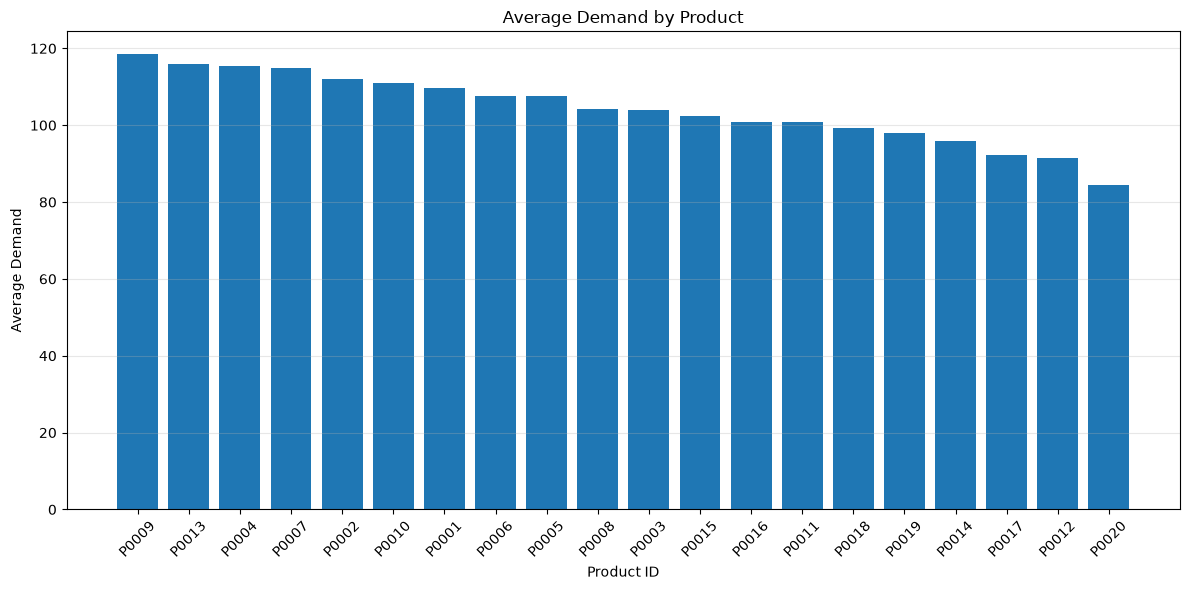

In [3]:
plt.figure(figsize=(12, 6))

plt.bar(
    product_analysis.index,
    product_analysis["Average_Demand"]
)

plt.xlabel("Product ID")
plt.ylabel("Average Demand")
plt.title("Average Demand by Product")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

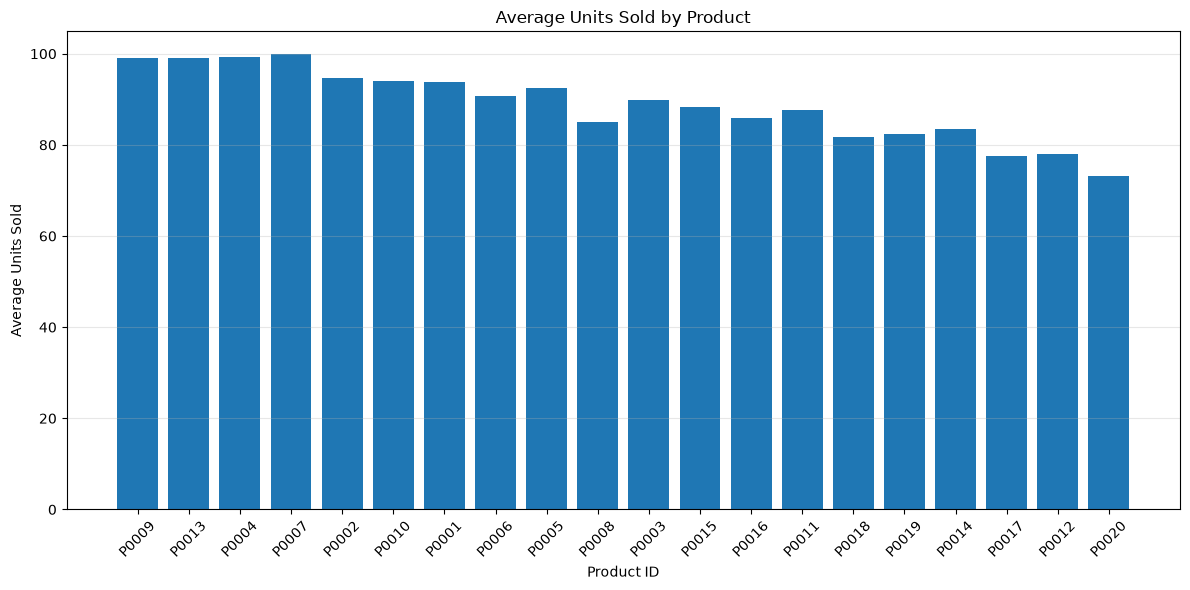

In [4]:
plt.figure(figsize=(12, 6))

plt.bar(
    product_analysis.index,
    product_analysis["Average_Units_Sold"]
)

plt.xlabel("Product ID")
plt.ylabel("Average Units Sold")
plt.title("Average Units Sold by Product")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

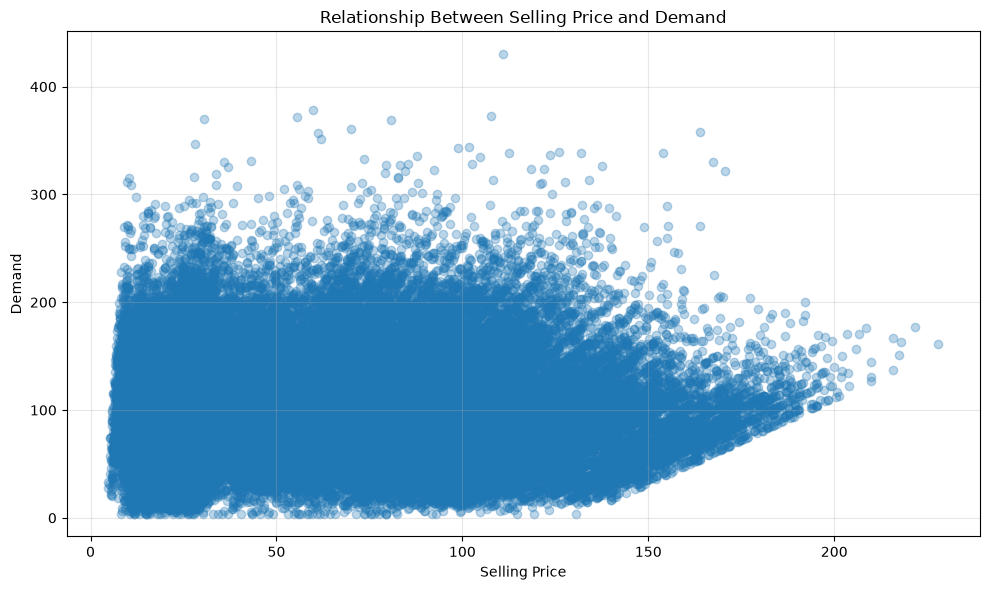

In [5]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Price"],
    df["Demand"],
    alpha=0.3
)

plt.xlabel("Selling Price")
plt.ylabel("Demand")
plt.title("Relationship Between Selling Price and Demand")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
df["Price_Group"] = pd.qcut(
    df["Price"],
    q=4,
    labels=["Low Price", "Medium-Low Price", "Medium-High Price", "High Price"]
)

price_analysis = (
    df.groupby("Price_Group", observed=False)
    .agg(
        Average_Demand=("Demand", "mean"),
        Average_Units_Sold=("Units Sold", "mean"),
        Average_Price=("Price", "mean"),
        Number_of_Records=("Demand", "count")
    )
    .round(2)
)

display(price_analysis)

,Average_Demand,Average_Units_Sold,Average_Price,Number_of_Records
Price_Group,,,,
Low Price,102.13,86.64,21.14,19000
Medium-Low Price,106.73,90.75,48.77,19002
Medium-High Price,108.84,92.96,79.57,19006
High Price,99.56,84.96,121.44,18992


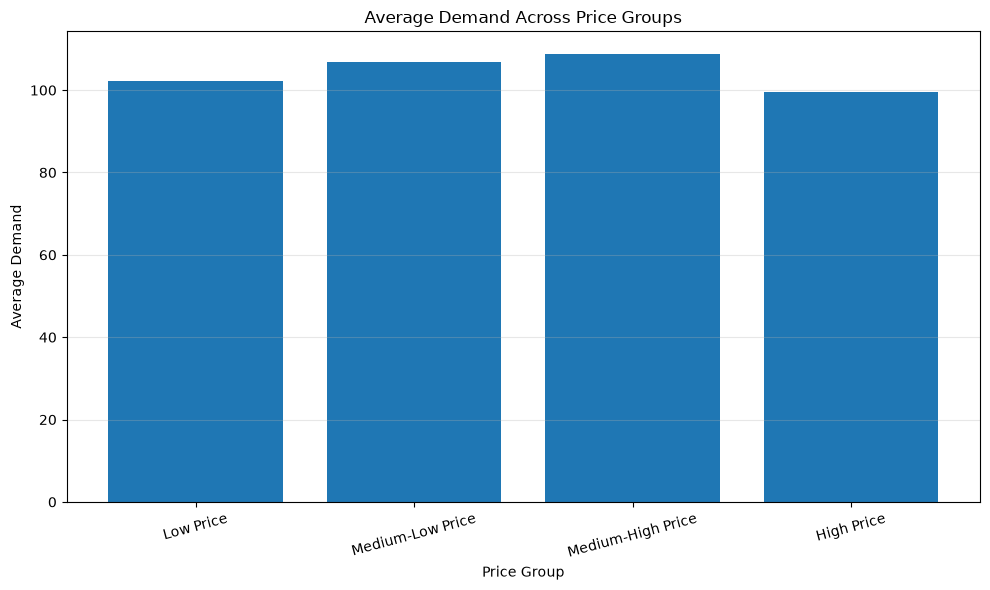

In [7]:
plt.figure(figsize=(10, 6))

plt.bar(
    price_analysis.index.astype(str),
    price_analysis["Average_Demand"]
)

plt.xlabel("Price Group")
plt.ylabel("Average Demand")
plt.title("Average Demand Across Price Groups")

plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
discount_analysis = (
    df.groupby("Discount")
    .agg(
        Average_Demand=("Demand", "mean"),
        Average_Units_Sold=("Units Sold", "mean"),
        Average_Price=("Price", "mean"),
        Number_of_Records=("Demand", "count")
    )
    .round(2)
    .sort_index()
)

display(discount_analysis)

,Average_Demand,Average_Units_Sold,Average_Price,Number_of_Records
Discount,,,,
0,94.75,81.57,73.07,17126
5,94.94,81.69,68.53,16918
10,102.77,87.66,66.93,23298
15,123.58,102.88,67.08,6245
20,124.07,103.77,63.45,6191
25,122.97,103.59,58.74,6222


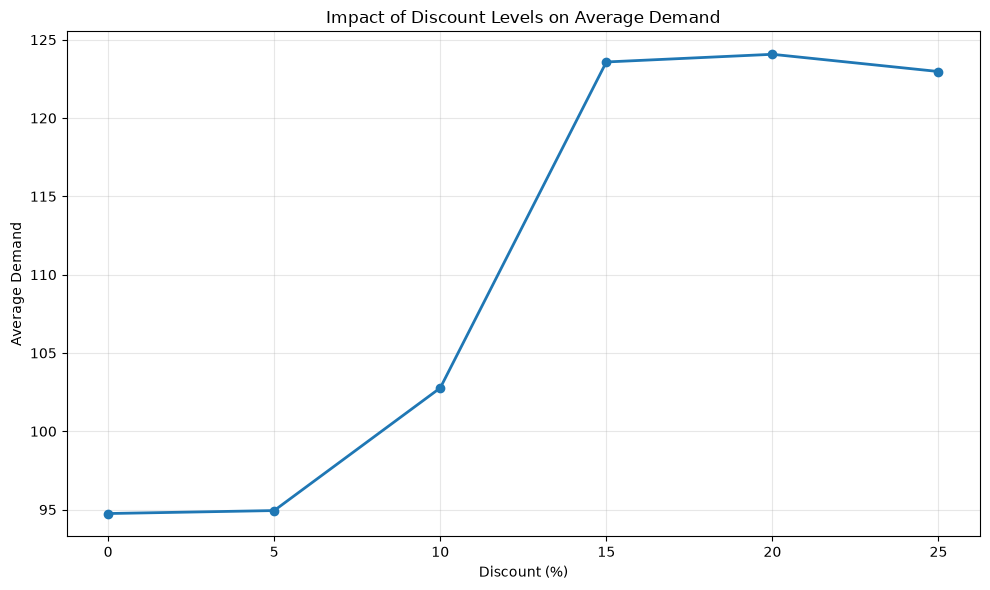

In [9]:
plt.figure(figsize=(10, 6))

plt.plot(
    discount_analysis.index,
    discount_analysis["Average_Demand"],
    marker="o",
    linewidth=2
)

plt.xlabel("Discount (%)")
plt.ylabel("Average Demand")
plt.title("Impact of Discount Levels on Average Demand")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
promotion_analysis = (
    df.groupby("Promotion")
    .agg(
        Average_Demand=("Demand", "mean"),
        Average_Units_Sold=("Units Sold", "mean"),
        Average_Discount=("Discount", "mean"),
        Average_Price=("Price", "mean"),
        Number_of_Records=("Demand", "count")
    )
    .round(2)
)

display(promotion_analysis)

,Average_Demand,Average_Units_Sold,Average_Discount,Average_Price,Number_of_Records
Promotion,,,,,
0,95.03,81.83,4.98,68.92,51000
1,123.27,103.10,17.46,65.30,25000


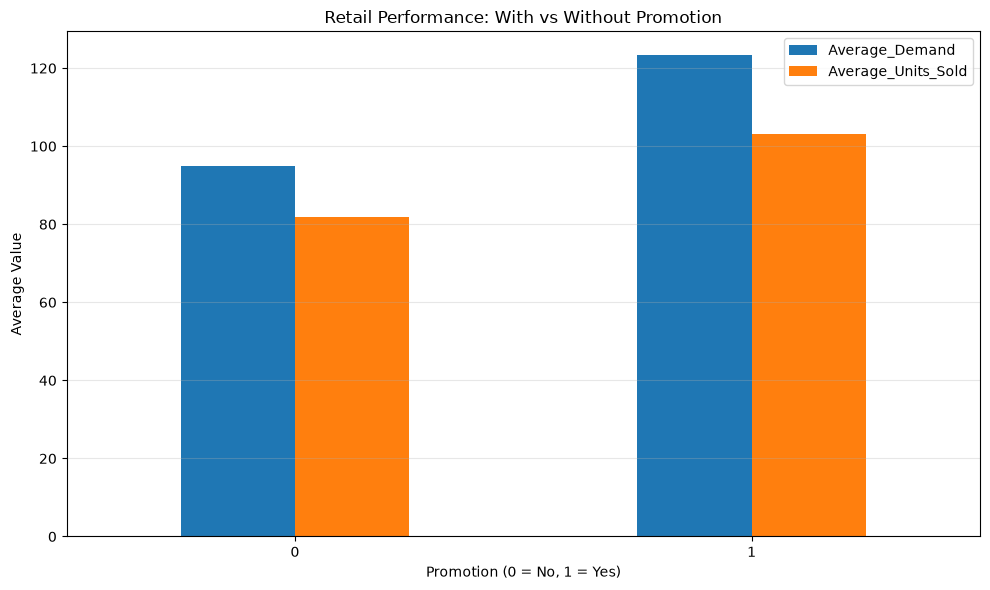

In [11]:
promotion_analysis[[
    "Average_Demand",
    "Average_Units_Sold"
]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Retail Performance: With vs Without Promotion")
plt.xlabel("Promotion (0 = No, 1 = Yes)")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
inventory_analysis = (
    df.groupby(
        pd.cut(
            df["Inventory Level"],
            bins=[-1, 50, 100, 200, 400, float("inf")],
            labels=["0-50", "51-100", "101-200", "201-400", "400+"]
        ),
        observed=False
    )
    .agg(
        Average_Demand=("Demand", "mean"),
        Average_Units_Sold=("Units Sold", "mean"),
        Average_Inventory=("Inventory Level", "mean"),
        Number_of_Records=("Demand", "count")
    )
    .round(2)
)

display(inventory_analysis)

,Average_Demand,Average_Units_Sold,Average_Inventory,Number_of_Records
Inventory Level,,,,
0-50,104.74,23.48,24.72,1620
51-100,92.79,63.81,81.30,7392
101-200,101.86,86.87,146.58,24674
201-400,103.70,93.17,288.06,22737
400+,112.46,101.11,616.72,19577


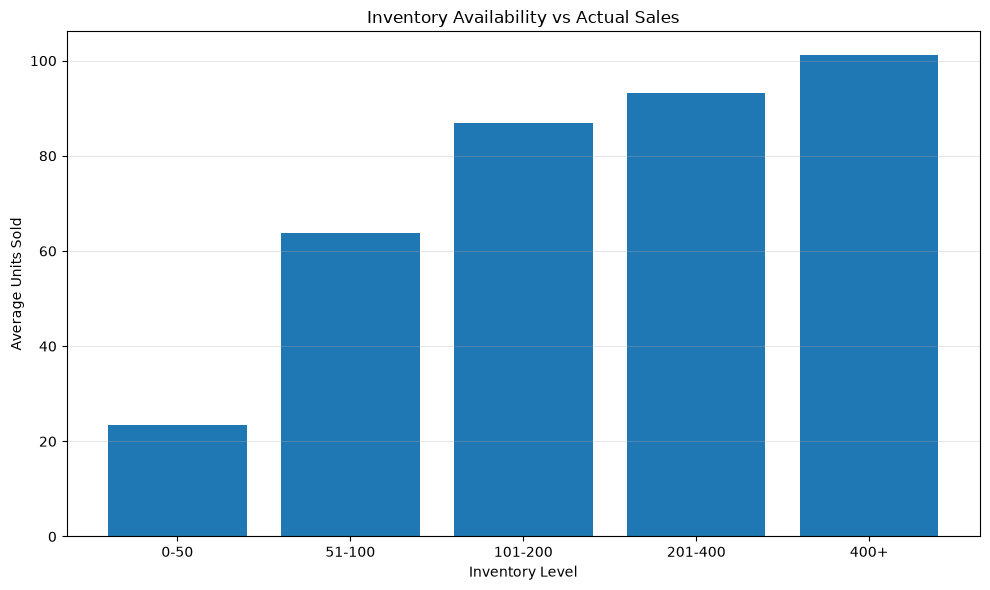

In [13]:
plt.figure(figsize=(10, 6))

plt.bar(
    inventory_analysis.index.astype(str),
    inventory_analysis["Average_Units_Sold"]
)

plt.xlabel("Inventory Level")
plt.ylabel("Average Units Sold")
plt.title("Inventory Availability vs Actual Sales")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
region_analysis = (
    df.groupby("Region")
    .agg(
        Average_Demand=("Demand", "mean"),
        Average_Units_Sold=("Units Sold", "mean"),
        Total_Units_Sold=("Units Sold", "sum"),
        Average_Price=("Price", "mean"),
        Number_of_Records=("Demand", "count")
    )
    .round(2)
    .sort_values("Average_Demand", ascending=False)
)

display(region_analysis)

,Average_Demand,Average_Units_Sold,Total_Units_Sold,Average_Price,Number_of_Records
Region,,,,,
South,106.94,91.19,1386126,64.40,15200
East,106.47,90.50,1375613,70.09,15200
North,103.77,88.19,2680946,63.36,30400
West,100.63,86.07,1308191,77.41,15200


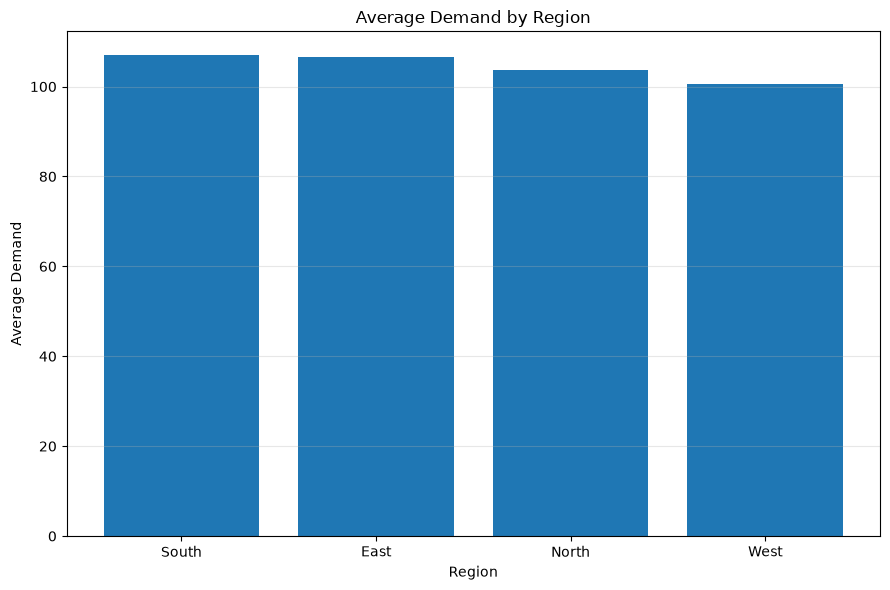

In [15]:
plt.figure(figsize=(9, 6))

plt.bar(
    region_analysis.index,
    region_analysis["Average_Demand"]
)

plt.xlabel("Region")
plt.ylabel("Average Demand")
plt.title("Average Demand by Region")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
regional_discount_analysis = (
    df.groupby("Region")
    .agg(
        Average_Discount=("Discount", "mean"),
        Average_Price=("Price", "mean"),
        Average_Demand=("Demand", "mean"),
        Average_Units_Sold=("Units Sold", "mean")
    )
    .round(2)
    .sort_values("Average_Discount", ascending=False)
)

display(regional_discount_analysis)

,Average_Discount,Average_Price,Average_Demand,Average_Units_Sold
Region,,,,
South,9.10,64.40,106.94,91.19
West,9.09,77.41,100.63,86.07
North,9.08,63.36,103.77,88.19
East,9.08,70.09,106.47,90.50


In [17]:
category_region_analysis = (
    df.groupby(["Region", "Category"])
    .agg(
        Average_Demand=("Demand", "mean"),
        Average_Units_Sold=("Units Sold", "mean"),
        Total_Units_Sold=("Units Sold", "sum")
    )
    .round(2)
)

display(category_region_analysis)

Average_Demand  Average_Units_Sold  Total_Units_Sold
Region Category                                                         
East   Clothing             109.46               94.63            143842
       Electronics          107.98               91.56            208763
       Furniture             73.41               64.64            147374
       Groceries            121.11              101.73            695831
       Toys                  92.08               78.86            179803
North  Clothing             123.05              101.65            309027
       Electronics           93.58               79.68            302787
       Furniture             73.71               64.79            344705
       Groceries            120.83              103.17           1254531
       Toys                  92.69               77.29            469896
South  Clothing             108.04               90.31            343180
       Electronics           93.96               82.93            189089
       Furniture             73.29               64.24             48824
       Groceries            120.59              101.98            620053
       Toys                  92.91               81.13            184980
West   Clothing             110.12               93.37            354824
       Electronics           96.07               74.60             56696
       Furniture             73.56               63.86            339751
       Groceries            121.58              104.68            556920

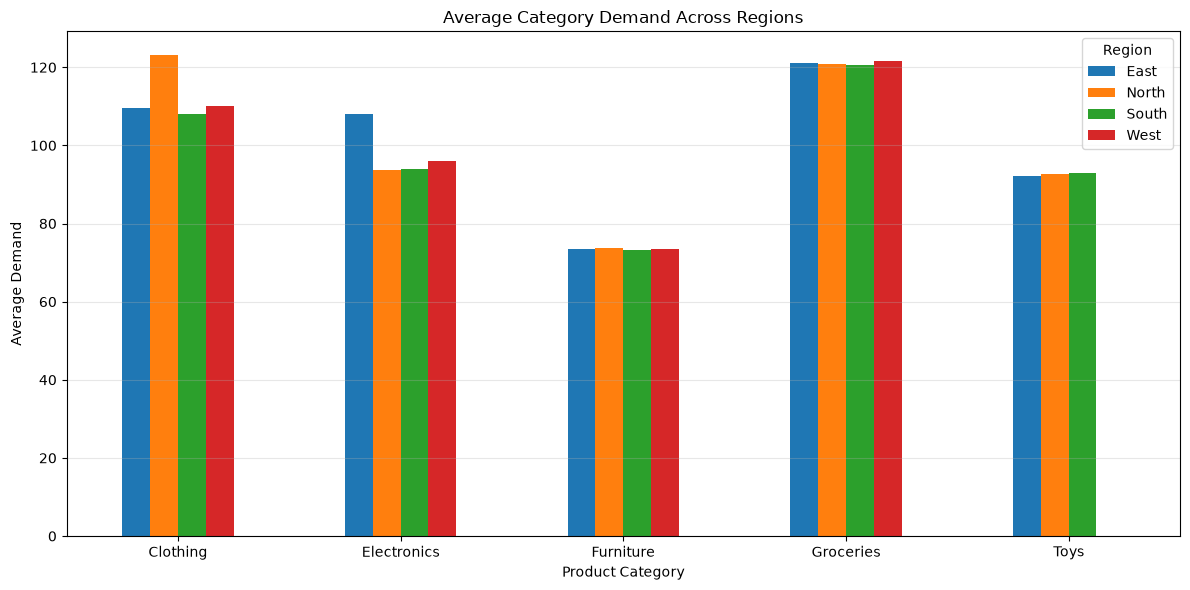

In [18]:
category_demand_pivot = df.pivot_table(
    index="Category",
    columns="Region",
    values="Demand",
    aggfunc="mean"
)

category_demand_pivot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Category Demand Across Regions")
plt.xlabel("Product Category")
plt.ylabel("Average Demand")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Region")
plt.tight_layout()
plt.show()

In [19]:
df["Revenue"] = df["Price"] * df["Units Sold"]

category_revenue = (
    df.groupby("Category")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Average_Revenue=("Revenue", "mean"),
        Total_Units_Sold=("Units Sold", "sum"),
        Average_Price=("Price", "mean")
    )
    .round(2)
    .sort_values("Total_Revenue", ascending=False)
)

display(category_revenue)

,Total_Revenue,Average_Revenue,Total_Units_Sold,Average_Price
Category,,,,
Groceries,1.688645e+08,5554.75,3127335,51.66
Furniture,1.112836e+08,8134.76,880654,121.51
Clothing,8.520061e+07,7006.63,1150873,71.52
Electronics,6.603987e+07,7241.21,757335,83.17
Toys,2.391155e+07,2247.33,834679,26.91


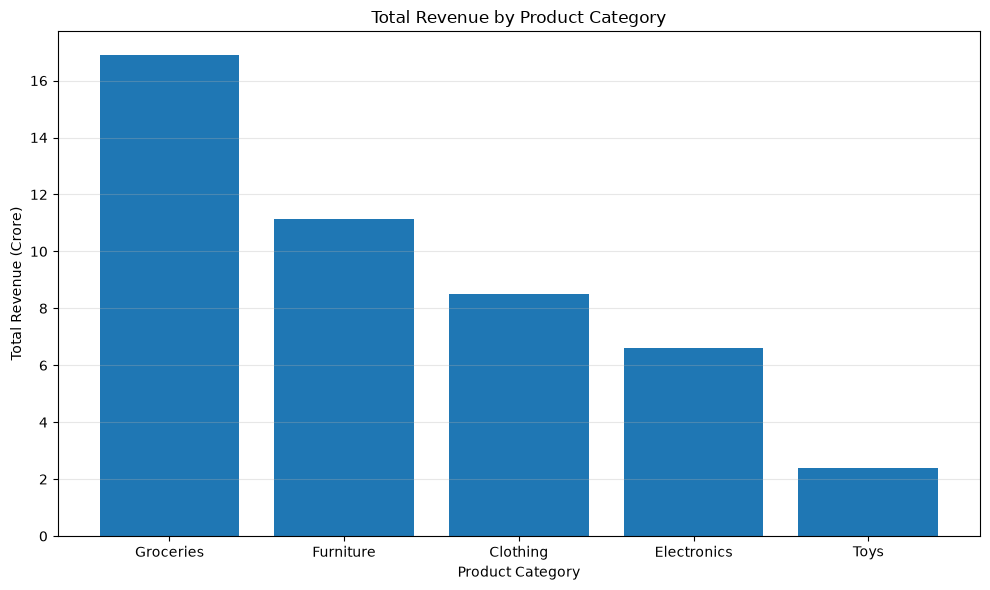

In [20]:
plt.figure(figsize=(10, 6))

plt.bar(
    category_revenue.index,
    category_revenue["Total_Revenue"] / 10000000
)

plt.xlabel("Product Category")
plt.ylabel("Total Revenue (Crore)")
plt.title("Total Revenue by Product Category")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
region_revenue = (
    df.groupby("Region")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Average_Revenue=("Revenue", "mean"),
        Total_Units_Sold=("Units Sold", "sum"),
        Average_Price=("Price", "mean")
    )
    .round(2)
    .sort_values("Total_Revenue", ascending=False)
)

display(region_revenue)

,Total_Revenue,Average_Revenue,Total_Units_Sold,Average_Price
Region,,,,
North,1.700080e+08,5592.37,2680946,63.36
East,9.852631e+07,6481.99,1375613,70.09
West,9.446692e+07,6214.93,1308191,77.41
South,9.229884e+07,6072.29,1386126,64.40


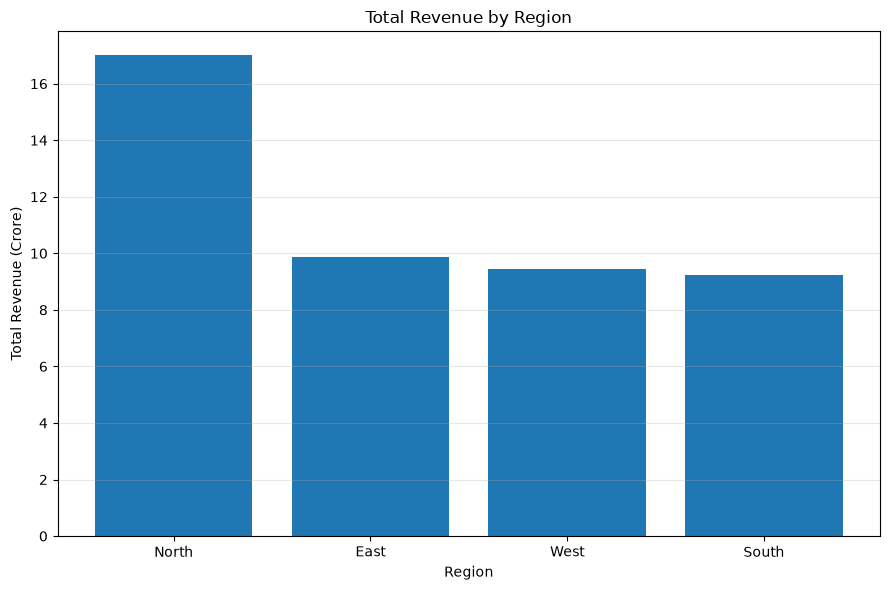

In [22]:
plt.figure(figsize=(9, 6))

plt.bar(
    region_revenue.index,
    region_revenue["Total_Revenue"] / 10000000
)

plt.xlabel("Region")
plt.ylabel("Total Revenue (Crore)")
plt.title("Total Revenue by Region")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
discount_revenue = (
    df.groupby("Discount")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Average_Revenue=("Revenue", "mean"),
        Average_Demand=("Demand", "mean"),
        Average_Units_Sold=("Units Sold", "mean"),
        Number_of_Records=("Demand", "count")
    )
    .round(2)
)

display(discount_revenue)

,Total_Revenue,Average_Revenue,Average_Demand,Average_Units_Sold,Number_of_Records
Discount,,,,,
0,1.012555e+08,5912.38,94.75,81.57,17126
5,9.411632e+07,5563.09,94.94,81.69,16918
10,1.371538e+08,5886.93,102.77,87.66,23298
15,4.353611e+07,6971.35,123.58,102.88,6245
20,4.103431e+07,6628.06,124.07,103.77,6191
25,3.820414e+07,6140.17,122.97,103.59,6222


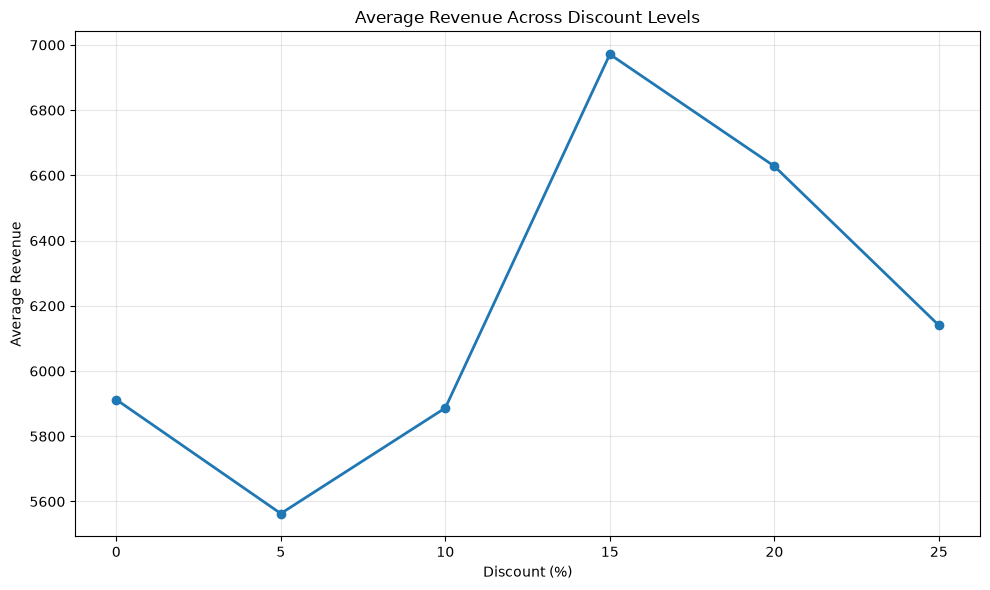

In [24]:
plt.figure(figsize=(10, 6))

plt.plot(
    discount_revenue.index,
    discount_revenue["Average_Revenue"],
    marker="o",
    linewidth=2
)

plt.xlabel("Discount (%)")
plt.ylabel("Average Revenue")
plt.title("Average Revenue Across Discount Levels")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
category_discount_analysis = (
    df.groupby(["Category", "Discount"])
    .agg(
        Average_Demand=("Demand", "mean"),
        Average_Units_Sold=("Units Sold", "mean"),
        Average_Revenue=("Revenue", "mean"),
        Number_of_Records=("Demand", "count")
    )
    .round(2)
)

display(category_discount_analysis)

Average_Demand  Average_Units_Sold  Average_Revenue  \
Category    Discount                                                        
Clothing    0                 102.58               87.32          6920.08   
            5                 102.39               87.30          6523.26   
            10                112.01               93.98          6910.55   
            15                134.22              108.79          8166.79   
            20                131.44              109.24          7583.55   
            25                131.32              109.49          7248.82   
Electronics 0                  88.29               75.98          7128.07   
            5                  87.54               75.30          6582.24   
            10                 96.81               82.52          7169.10   
            15                116.91               97.42          8499.28   
            20                116.16               98.29          8153.01   
            25                114.66               96.24          7458.82   
Furniture   0                  66.41               58.42          7936.66   
            5                  66.83               58.73          7567.89   
            10                 72.45               63.77          8042.04   
            15                 87.61               75.79          9410.47   
            20                 87.80               75.19          8905.94   
            25                 88.51               76.83          8531.52   
Groceries   0                 109.72               94.43          5440.84   
            5                 110.72               94.89          5200.52   
            10                118.89              101.48          5433.07   
            15                143.51              119.66          6499.71   
            20                143.74              119.81          6271.41   
            25                141.52              118.71          5596.67   
Toys        0                  85.39               73.16          2261.22   
            5                  83.87               72.64          2101.05   
            10                 90.53               76.34          2182.47   
            15                106.94               87.97          2522.25   
            20                111.08               91.78          2476.66   
            25                110.48               93.31          2351.59   

                      Number_of_Records  
Category    Discount                     
Clothing    0                      2751  
            5                      2737  
            10                     3733  
            15                      964  
            20                      965  
            25                     1010  
Electronics 0                      2081  
            5                      2045  
            10                     2751  
            15                      762  
            20                      721  
            25                      760  
Furniture   0                      3140  
            5                      3013  
            10                     4215  
            15                     1132  
            20                     1100  
            25                     1080  
Groceries   0                      6845  
            5                      6721  
            10                     9303  
            15                     2512  
            20                     2532  
            25                     2487  
Toys        0                      2309  
            5                      2402  
            10                     3296  
            15                      875  
            20                      873  
            25                      885

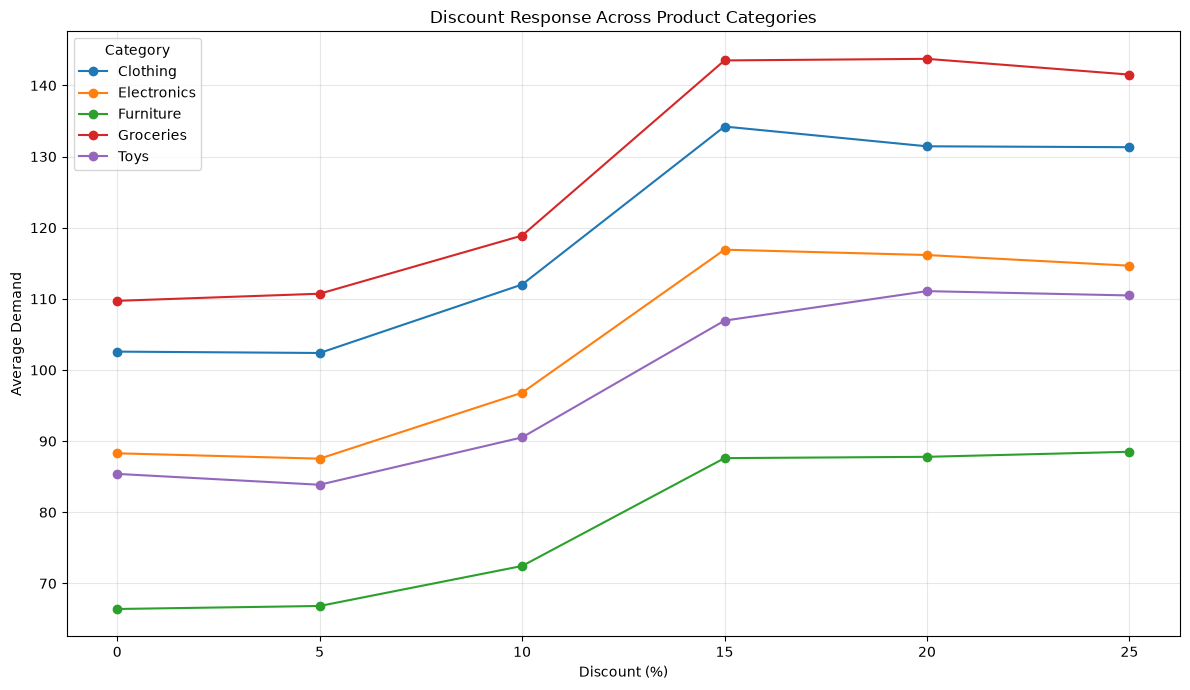

In [26]:
category_discount_pivot = df.pivot_table(
    index="Discount",
    columns="Category",
    values="Demand",
    aggfunc="mean"
)

category_discount_pivot.plot(
    kind="line",
    marker="o",
    figsize=(12, 7)
)

plt.title("Discount Response Across Product Categories")
plt.xlabel("Discount (%)")
plt.ylabel("Average Demand")
plt.legend(title="Category")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
product_revenue = (
    df.groupby("Product ID")
    .agg(
        Category=("Category", "first"),
        Total_Revenue=("Revenue", "sum"),
        Average_Revenue=("Revenue", "mean"),
        Total_Units_Sold=("Units Sold", "sum"),
        Average_Price=("Price", "mean")
    )
    .round(2)
    .sort_values("Total_Revenue", ascending=False)
)

display(product_revenue)

,Category,Total_Revenue,Average_Revenue,Total_Units_Sold,Average_Price
Product ID,,,,,
P0014,Groceries,37032696.67,9745.45,317397,118.60
P0011,Furniture,33594079.05,8840.55,332883,99.62
P0009,Clothing,32556739.83,8567.56,376771,83.05
P0012,Groceries,28109019.41,7397.11,296256,93.20
P0019,Furniture,26541017.90,6984.48,313209,86.72
P0003,Clothing,26332779.37,6929.68,341531,76.36
P0020,Furniture,25165063.85,6622.39,277961,90.75
P0016,Groceries,23900336.27,6289.56,326718,72.66
P0010,Furniture,23061113.11,6068.71,357299,66.47


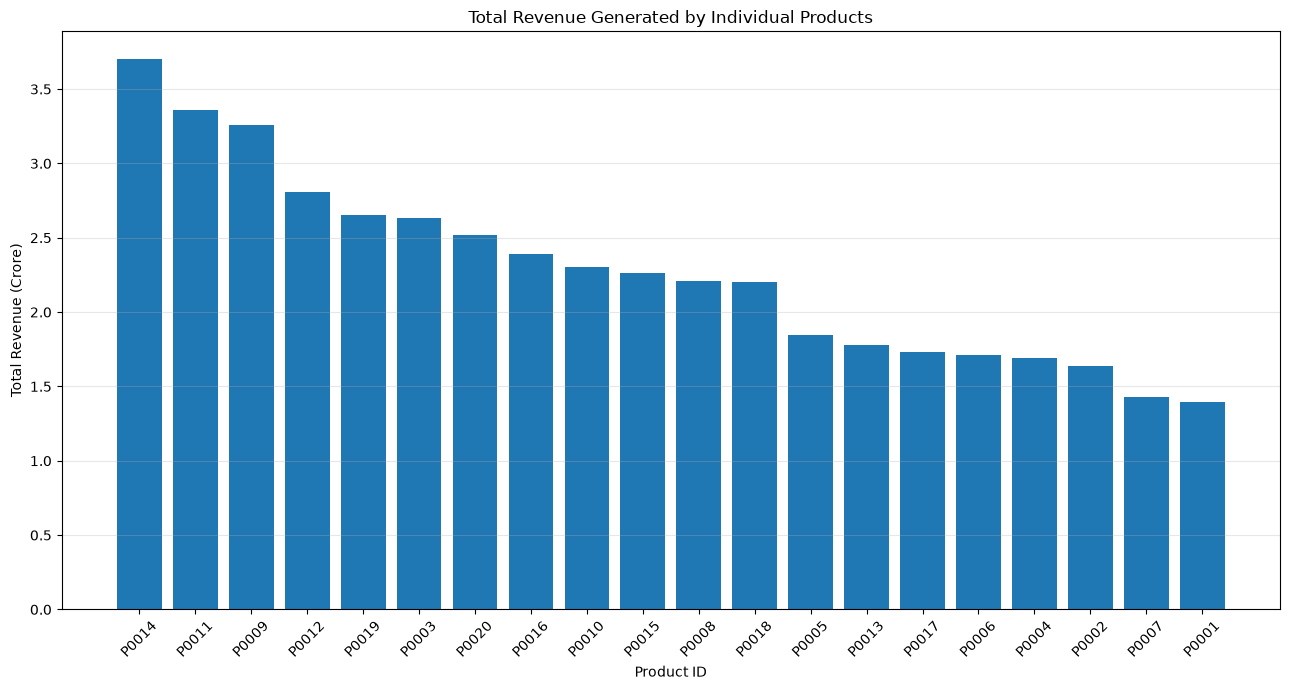

In [28]:
plt.figure(figsize=(13, 7))

plt.bar(
    product_revenue.index,
    product_revenue["Total_Revenue"] / 10000000
)

plt.xlabel("Product ID")
plt.ylabel("Total Revenue (Crore)")
plt.title("Total Revenue Generated by Individual Products")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

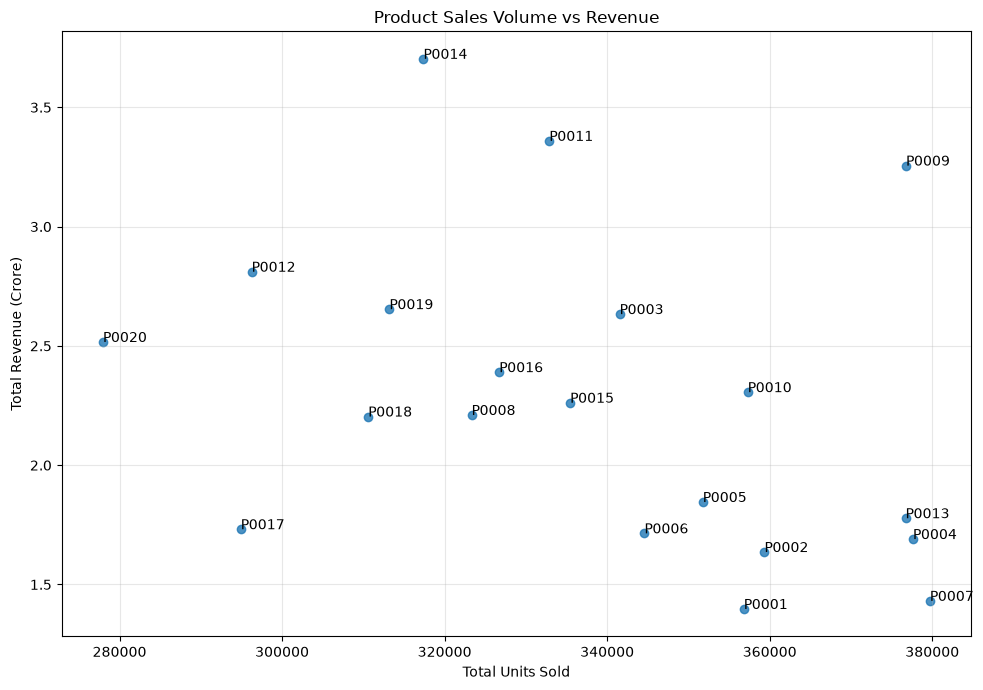

In [29]:
plt.figure(figsize=(10, 7))

plt.scatter(
    product_revenue["Total_Units_Sold"],
    product_revenue["Total_Revenue"] / 10000000,
    alpha=0.8
)

for product in product_revenue.index:
    plt.annotate(
        product,
        (
            product_revenue.loc[product, "Total_Units_Sold"],
            product_revenue.loc[product, "Total_Revenue"] / 10000000
        )
    )

plt.xlabel("Total Units Sold")
plt.ylabel("Total Revenue (Crore)")
plt.title("Product Sales Volume vs Revenue")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
product_average_revenue = (
    df.groupby(["Product ID", "Category"])
    .agg(
        Average_Revenue=("Revenue", "mean"),
        Average_Units_Sold=("Units Sold", "mean"),
        Average_Price=("Price", "mean"),
        Average_Demand=("Demand", "mean")
    )
    .round(2)
    .sort_values("Average_Revenue", ascending=False)
)

display(product_average_revenue)

,,Average_Revenue,Average_Units_Sold,Average_Price,Average_Demand
Product ID,Category,,,,
P0008,Clothing,10789.47,93.17,112.52,109.25
P0011,Furniture,10591.39,67.32,150.78,74.25
P0014,Furniture,10476.07,64.77,155.56,74.52
P0009,Clothing,10271.68,98.75,101.20,114.99
P0011,Groceries,10075.28,101.52,94.96,119.29
...,...,...,...,...,...
P0018,Clothing,2240.76,89.49,24.46,114.43
P0017,Toys,2035.94,76.68,25.00,92.85
P0005,Toys,1808.26,81.05,20.87,91.59


In [31]:
product_category_check = (
    df.groupby("Product ID")["Category"]
    .nunique()
    .sort_values(ascending=False)
)

display(product_category_check)

Product ID
P0003    5
P0016    5
P0005    4
P0002    4
P0015    4
P0008    4
P0011    4
P0001    3
P0019    3
P0014    3
P0012    3
P0006    3
P0020    3
P0018    3
P0017    3
P0004    2
P0009    2
P0010    2
P0007    2
P0013    2
Name: Category, dtype: int64

In [32]:
df[
    df["Product ID"] == "P0003"
][["Product ID", "Category", "Price", "Units Sold", "Demand"]].head(15)

,Product ID,Category,Price,Units Sold,Demand
2,P0003,Clothing,62.94,114,157
22,P0003,Groceries,95.17,167,171
42,P0003,Electronics,83.17,122,126
62,P0003,Furniture,134.16,92,114
82,P0003,Toys,29.57,145,143
102,P0003,Clothing,66.15,130,156
122,P0003,Groceries,66.64,20,58
142,P0003,Electronics,109.88,125,145
162,P0003,Furniture,142.86,69,81
182,P0003,Toys,29.13,87,100


In [33]:
product_revenue_corrected = (
    df.groupby(["Category", "Product ID"])
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Average_Revenue=("Revenue", "mean"),
        Total_Units_Sold=("Units Sold", "sum"),
        Average_Units_Sold=("Units Sold", "mean"),
        Average_Price=("Price", "mean"),
        Average_Demand=("Demand", "mean"),
        Number_of_Records=("Demand", "count")
    )
    .round(2)
    .sort_values("Total_Revenue", ascending=False)
)

display(product_revenue_corrected)

Total_Revenue  Average_Revenue  Total_Units_Sold  \
Category  Product ID                                                     
Furniture P0020         17925202.36          7861.93            146598   
Groceries P0010         16983572.73          5586.70            308032   
          P0009         16943785.15          7431.48            226674   
Furniture P0014         15923624.85         10476.07             98449   
Groceries P0013         15901559.54          5230.78            319111   
...                             ...              ...               ...   
Toys      P0020          1753306.36          2306.98             58332   
          P0007          1717889.29          2260.38             61349   
          P0005          1374278.08          1808.26             61601   
          P0001           953234.58          1254.26             58428   
          P0015           903600.28          1188.95             57825   

                      Average_Units_Sold  Average_Price  Average_Demand  \
Category  Product ID                                                      
Furniture P0020                    64.30         117.62           73.49   
Groceries P0010                   101.33          53.40          120.66   
          P0009                    99.42          70.95          120.85   
Furniture P0014                    64.77         155.56           74.52   
Groceries P0013                   104.97          47.70          121.83   
...                                  ...            ...             ...   
Toys      P0020                    76.75          28.47           92.04   
          P0007                    80.72          26.25           91.87   
          P0005                    81.05          20.87           91.59   
          P0001                    76.88          15.46           91.44   
          P0015                    76.09          14.75           91.25   

                      Number_of_Records  
Category  Product ID                     
Furniture P0020                    2280  
Groceries P0010                    3040  
          P0009                    2280  
Furniture P0014                    1520  
Groceries P0013                    3040  
...                                 ...  
Toys      P0020                     760  
          P0007                     760  
          P0005                     760  
          P0001                     760  
          P0015                     760  

[64 rows x 7 columns]

In [34]:
top_10_products = product_revenue_corrected.head(10)

display(top_10_products)

Total_Revenue  Average_Revenue  Total_Units_Sold  \
Category    Product ID                                                     
Furniture   P0020         17925202.36          7861.93            146598   
Groceries   P0010         16983572.73          5586.70            308032   
            P0009         16943785.15          7431.48            226674   
Furniture   P0014         15923624.85         10476.07             98449   
Groceries   P0013         15901559.54          5230.78            319111   
Clothing    P0009         15612954.68         10271.68            150097   
Groceries   P0014         13703192.03          9015.26            157049   
Furniture   P0018         13639948.53          8973.65             96135   
Electronics P0011         13461761.62          8856.42            131332   
Groceries   P0007         12595805.06          4143.36            318360   

                        Average_Units_Sold  Average_Price  Average_Demand  \
Category    Product ID                                                      
Furniture   P0020                    64.30         117.62           73.49   
Groceries   P0010                   101.33          53.40          120.66   
            P0009                    99.42          70.95          120.85   
Furniture   P0014                    64.77         155.56           74.52   
Groceries   P0013                   104.97          47.70          121.83   
Clothing    P0009                    98.75         101.20          114.99   
Groceries   P0014                   103.32          83.38          118.69   
Furniture   P0018                    63.25         137.03           72.77   
Electronics P0011                    86.40          96.94           99.85   
Groceries   P0007                   104.72          38.03          120.81   

                        Number_of_Records  
Category    Product ID                     
Furniture   P0020                    2280  
Groceries   P0010                    3040  
            P0009                    2280  
Furniture   P0014                    1520  
Groceries   P0013                    3040  
Clothing    P0009                    1520  
Groceries   P0014                    1520  
Furniture   P0018                    1520  
Electronics P0011                    1520  
Groceries   P0007                    3040

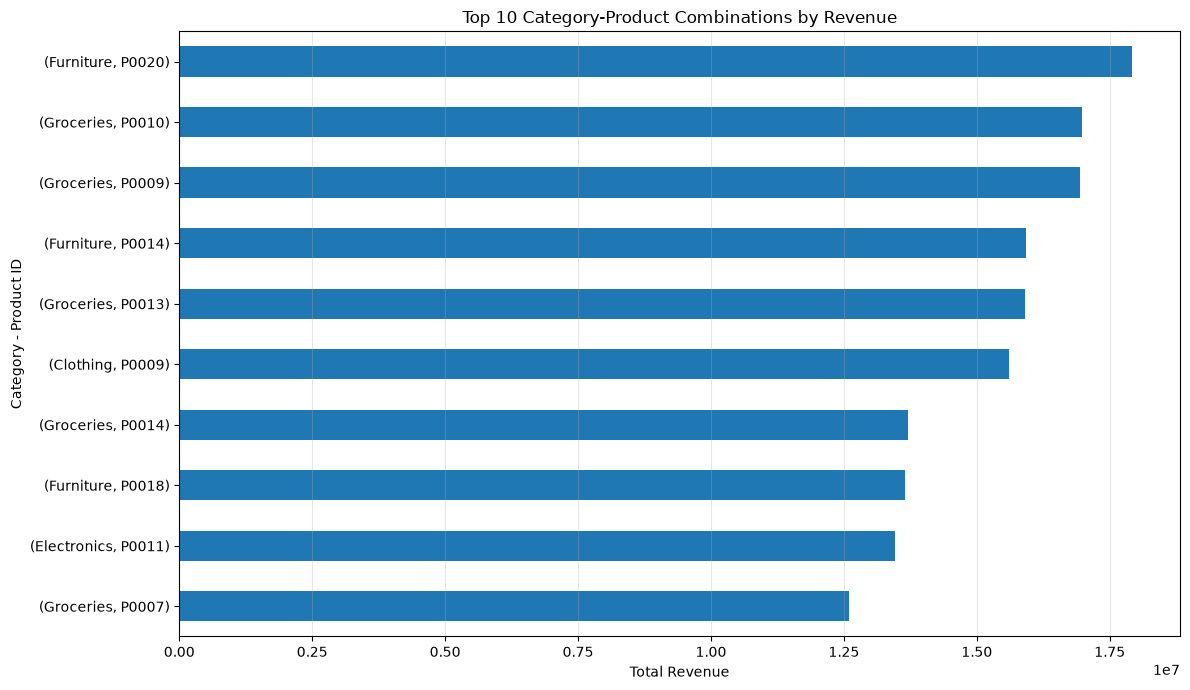

In [35]:
plt.figure(figsize=(12, 7))

top_10_products["Total_Revenue"].sort_values().plot(
    kind="barh"
)

plt.xlabel("Total Revenue")
plt.ylabel("Category - Product ID")
plt.title("Top 10 Category-Product Combinations by Revenue")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:
category_revenue_comparison = (
    df.groupby("Category")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Average_Revenue=("Revenue", "mean"),
        Total_Units_Sold=("Units Sold", "sum"),
        Average_Units_Sold=("Units Sold", "mean"),
        Average_Price=("Price", "mean"),
        Average_Demand=("Demand", "mean")
    )
    .round(2)
    .sort_values("Total_Revenue", ascending=False)
)

display(category_revenue_comparison)

,Total_Revenue,Average_Revenue,Total_Units_Sold,Average_Units_Sold,Average_Price,Average_Demand
Category,,,,,,
Groceries,1.688645e+08,5554.75,3127335,102.87,51.66,120.98
Furniture,1.112836e+08,8134.76,880654,64.38,121.51,73.58
Clothing,8.520061e+07,7006.63,1150873,94.64,71.52,112.62
Electronics,6.603987e+07,7241.21,757335,83.04,83.17,97.48
Toys,2.391155e+07,2247.33,834679,78.45,26.91,92.61


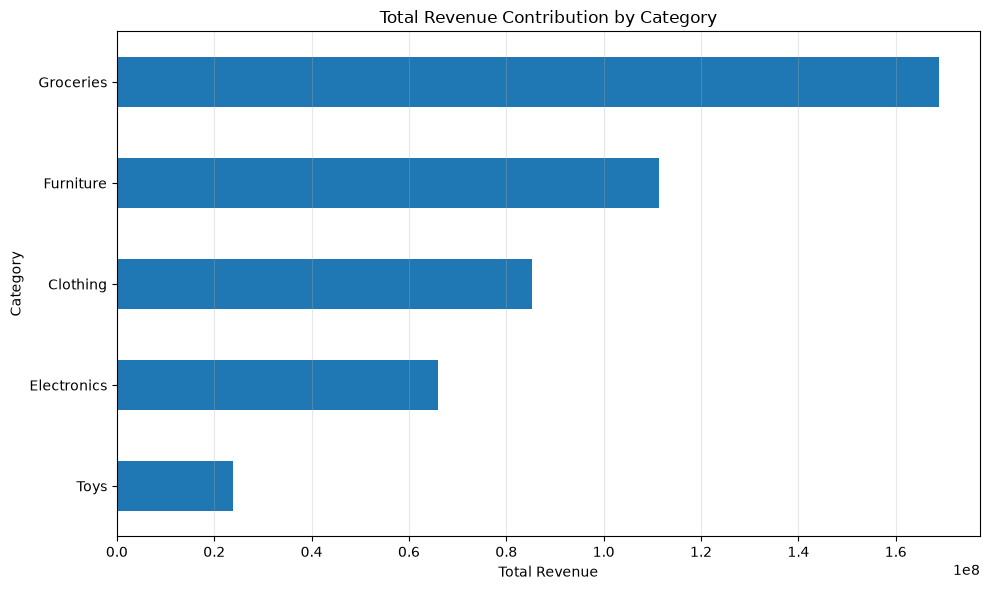

In [37]:
plt.figure(figsize=(10, 6))

category_revenue_comparison["Total_Revenue"].sort_values().plot(
    kind="barh"
)

plt.title("Total Revenue Contribution by Category")
plt.xlabel("Total Revenue")
plt.ylabel("Category")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [38]:
total_business_revenue = category_revenue_comparison["Total_Revenue"].sum()

category_revenue_comparison["Revenue_Contribution_%"] = (
    category_revenue_comparison["Total_Revenue"]
    / total_business_revenue
    * 100
).round(2)

display(
    category_revenue_comparison[
        ["Total_Revenue", "Revenue_Contribution_%"]
    ].sort_values("Revenue_Contribution_%", ascending=False)
)

,Total_Revenue,Revenue_Contribution_%
Category,,
Groceries,1.688645e+08,37.09
Furniture,1.112836e+08,24.44
Clothing,8.520061e+07,18.71
Electronics,6.603987e+07,14.50
Toys,2.391155e+07,5.25


In [39]:
category_revenue_comparison["Units_Contribution_%"] = (
    category_revenue_comparison["Total_Units_Sold"]
    / category_revenue_comparison["Total_Units_Sold"].sum()
    * 100
).round(2)

display(
    category_revenue_comparison[
        [
            "Revenue_Contribution_%",
            "Units_Contribution_%",
            "Average_Price"
        ]
    ].sort_values("Revenue_Contribution_%", ascending=False)
)

,Revenue_Contribution_%,Units_Contribution_%,Average_Price
Category,,,
Groceries,37.09,46.32,51.66
Furniture,24.44,13.05,121.51
Clothing,18.71,17.05,71.52
Electronics,14.50,11.22,83.17
Toys,5.25,12.36,26.91


In [40]:
category_revenue_comparison["Revenue_Per_Unit"] = (
    category_revenue_comparison["Total_Revenue"]
    / category_revenue_comparison["Total_Units_Sold"]
).round(2)

display(
    category_revenue_comparison[
        [
            "Average_Price",
            "Revenue_Per_Unit",
            "Average_Units_Sold"
        ]
    ].sort_values("Revenue_Per_Unit", ascending=False)
)

,Average_Price,Revenue_Per_Unit,Average_Units_Sold
Category,,,
Furniture,121.51,126.36,64.38
Electronics,83.17,87.20,83.04
Clothing,71.52,74.03,94.64
Groceries,51.66,54.00,102.87
Toys,26.91,28.65,78.45


In [41]:
price_discount_analysis = (
    df.groupby("Discount")
    .agg(
        Average_Price=("Price", "mean"),
        Average_Revenue_Per_Record=("Revenue", "mean"),
        Average_Units_Sold=("Units Sold", "mean"),
        Number_of_Records=("Demand", "count")
    )
    .round(2)
)

display(price_discount_analysis)

,Average_Price,Average_Revenue_Per_Record,Average_Units_Sold,Number_of_Records
Discount,,,,
0,73.07,5912.38,81.57,17126
5,68.53,5563.09,81.69,16918
10,66.93,5886.93,87.66,23298
15,67.08,6971.35,102.88,6245
20,63.45,6628.06,103.77,6191
25,58.74,6140.17,103.59,6222


In [42]:
category_discount_revenue = (
    df.groupby(["Category", "Discount"])
    .agg(
        Average_Revenue=("Revenue", "mean"),
        Average_Units_Sold=("Units Sold", "mean"),
        Average_Price=("Price", "mean"),
        Number_of_Records=("Demand", "count")
    )
    .round(2)
)

display(category_discount_revenue)

Average_Revenue  Average_Units_Sold  Average_Price  \
Category    Discount                                                       
Clothing    0                 6920.08               87.32          76.62   
            5                 6523.26               87.30          72.18   
            10                6910.55               93.98          70.73   
            15                8166.79              108.79          72.06   
            20                7583.55              109.24          66.59   
            25                7248.82              109.49          62.93   
Electronics 0                 7128.07               75.98          89.54   
            5                 6582.24               75.30          83.31   
            10                7169.10               82.52          82.49   
            15                8499.28               97.42          82.42   
            20                8153.01               98.29          78.27   
            25                7458.82               96.24          73.26   
Furniture   0                 7936.66               58.42         130.42   
            5                 7567.89               58.73         123.66   
            10                8042.04               63.77         120.30   
            15                9410.47               75.79         118.95   
            20                8905.94               75.19         112.97   
            25                8531.52               76.83         105.66   
Groceries   0                 5440.84               94.43          55.18   
            5                 5200.52               94.89          52.56   
            10                5433.07              101.48          50.88   
            15                6499.71              119.66          51.28   
            20                6271.41              119.81          49.75   
            25                5596.67              118.71          44.74   
Toys        0                 2261.22               73.16          29.03   
            5                 2101.05               72.64          27.29   
            10                2182.47               76.34          26.65   
            15                2522.25               87.97          26.49   
            20                2476.66               91.78          25.09   
            25                2351.59               93.31          23.57   

                      Number_of_Records  
Category    Discount                     
Clothing    0                      2751  
            5                      2737  
            10                     3733  
            15                      964  
            20                      965  
            25                     1010  
Electronics 0                      2081  
            5                      2045  
            10                     2751  
            15                      762  
            20                      721  
            25                      760  
Furniture   0                      3140  
            5                      3013  
            10                     4215  
            15                     1132  
            20                     1100  
            25                     1080  
Groceries   0                      6845  
            5                      6721  
            10                     9303  
            15                     2512  
            20                     2532  
            25                     2487  
Toys        0                      2309  
            5                      2402  
            10                     3296  
            15                      875  
            20                      873  
            25                      885

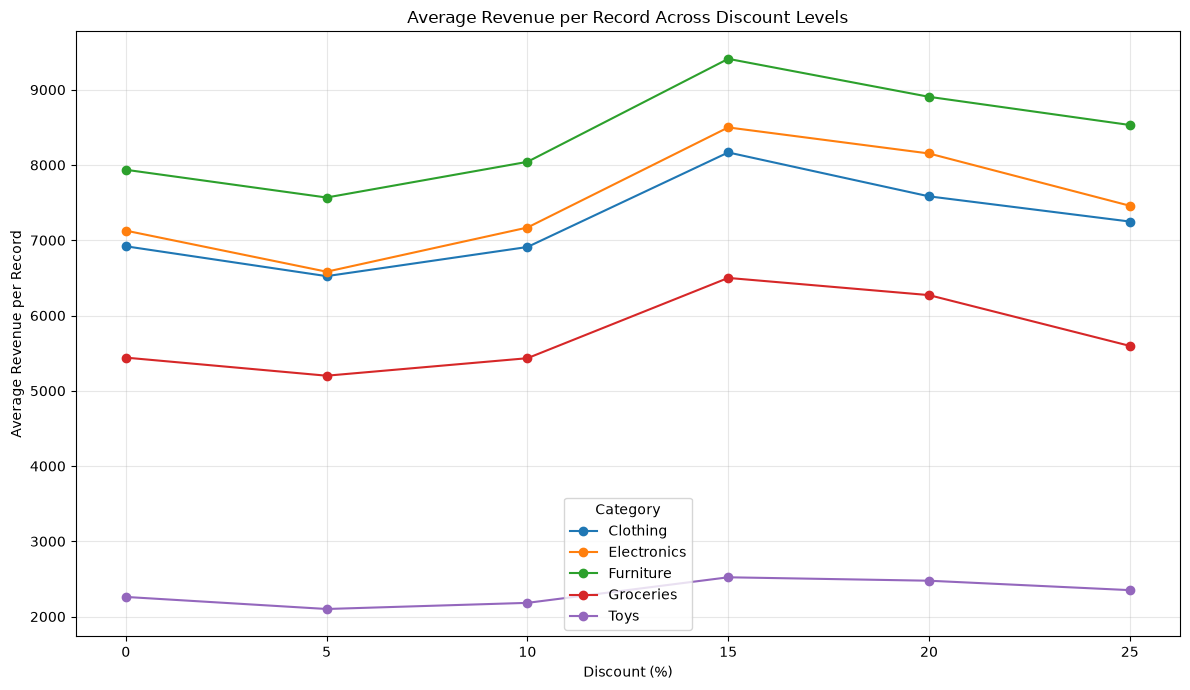

In [43]:
category_discount_pivot = df.pivot_table(
    index="Discount",
    columns="Category",
    values="Revenue",
    aggfunc="mean"
)

category_discount_pivot.plot(
    kind="line",
    marker="o",
    figsize=(12, 7)
)

plt.title("Average Revenue per Record Across Discount Levels")
plt.xlabel("Discount (%)")
plt.ylabel("Average Revenue per Record")
plt.legend(title="Category")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [44]:
cost_columns = [
    column for column in df.columns
    if any(word in column.lower()
           for word in ["cost", "expense", "profit", "margin"])
]

print("Potential cost and profitability columns:")
print(cost_columns)

print("\nAll dataset columns:")
print(df.columns.tolist())

Potential cost and profitability columns:
[]

All dataset columns:
['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount', 'Weather Condition', 'Promotion', 'Competitor Pricing', 'Seasonality', 'Epidemic', 'Demand', 'Price_Group', 'Revenue']


In [45]:
cost_model_base = (
    df.groupby("Category")
    .agg(
        Average_Price=("Price", "mean"),
        Average_Discount=("Discount", "mean"),
        Average_Units_Sold=("Units Sold", "mean")
    )
    .round(2)
)

display(cost_model_base)

,Average_Price,Average_Discount,Average_Units_Sold
Category,,,
Clothing,71.52,9.05,94.64
Electronics,83.17,9.06,83.04
Furniture,121.51,9.01,64.38
Groceries,51.66,9.12,102.87
Toys,26.91,9.18,78.45


In [46]:
assumed_cost_percentages = {
    "Clothing": 0.60,
    "Electronics": 0.70,
    "Furniture": 0.55,
    "Groceries": 0.75,
    "Toys": 0.65
}

cost_model_base["Assumed_Cost_Percent"] = (
    cost_model_base.index.map(assumed_cost_percentages)
)

cost_model_base["Estimated_Unit_Cost"] = (
    cost_model_base["Average_Price"]
    * cost_model_base["Assumed_Cost_Percent"]
).round(2)

display(cost_model_base)

,Average_Price,Average_Discount,Average_Units_Sold,Assumed_Cost_Percent,Estimated_Unit_Cost
Category,,,,,
Clothing,71.52,9.05,94.64,0.60,42.91
Electronics,83.17,9.06,83.04,0.70,58.22
Furniture,121.51,9.01,64.38,0.55,66.83
Groceries,51.66,9.12,102.87,0.75,38.74
Toys,26.91,9.18,78.45,0.65,17.49


In [47]:
cost_model_base["Estimated_Unit_Margin"] = (
    cost_model_base["Average_Price"]
    - cost_model_base["Estimated_Unit_Cost"]
).round(2)

cost_model_base["Estimated_Margin_%"] = (
    cost_model_base["Estimated_Unit_Margin"]
    / cost_model_base["Average_Price"]
    * 100
).round(2)

display(
    cost_model_base[
        [
            "Average_Price",
            "Estimated_Unit_Cost",
            "Estimated_Unit_Margin",
            "Estimated_Margin_%"
        ]
    ]
)

,Average_Price,Estimated_Unit_Cost,Estimated_Unit_Margin,Estimated_Margin_%
Category,,,,
Clothing,71.52,42.91,28.61,40.00
Electronics,83.17,58.22,24.95,30.00
Furniture,121.51,66.83,54.68,45.00
Groceries,51.66,38.74,12.92,25.01
Toys,26.91,17.49,9.42,35.01


In [48]:
discount_levels = [0, 5, 10, 15, 20, 25]

discount_scenarios = []

for category, row in cost_model_base.iterrows():
    for discount in discount_levels:

        selling_price = row["Average_Price"] * (1 - discount / 100)

        estimated_profit = selling_price - row["Estimated_Unit_Cost"]

        margin_percentage = (
            estimated_profit / selling_price * 100
            if selling_price > 0 else 0
        )

        discount_scenarios.append({
            "Category": category,
            "Discount": discount,
            "Selling_Price": round(selling_price, 2),
            "Unit_Cost": row["Estimated_Unit_Cost"],
            "Estimated_Profit_Per_Unit": round(estimated_profit, 2),
            "Estimated_Margin_%": round(margin_percentage, 2)
        })

discount_profit_analysis = pd.DataFrame(discount_scenarios)

display(discount_profit_analysis)

,Category,Discount,Selling_Price,Unit_Cost,Estimated_Profit_Per_Unit,Estimated_Margin_%
0,Clothing,0,71.52,42.91,28.61,40.00
1,Clothing,5,67.94,42.91,25.03,36.85
2,Clothing,10,64.37,42.91,21.46,33.34
3,Clothing,15,60.79,42.91,17.88,29.42
4,Clothing,20,57.22,42.91,14.31,25.00
5,Clothing,25,53.64,42.91,10.73,20.00
6,Electronics,0,83.17,58.22,24.95,30.00
7,Electronics,5,79.01,58.22,20.79,26.31
8,Electronics,10,74.85,58.22,16.63,22.22
9,Electronics,15,70.69,58.22,12.47,17.65


In [49]:
cost_model_base["Break_Even_Discount_%"] = (
    (
        cost_model_base["Average_Price"]
        - cost_model_base["Estimated_Unit_Cost"]
    )
    / cost_model_base["Average_Price"]
    * 100
).round(2)

display(
    cost_model_base[
        [
            "Average_Price",
            "Estimated_Unit_Cost",
            "Break_Even_Discount_%"
        ]
    ].sort_values(
        "Break_Even_Discount_%",
        ascending=False
    )
)

,Average_Price,Estimated_Unit_Cost,Break_Even_Discount_%
Category,,,
Furniture,121.51,66.83,45.00
Clothing,71.52,42.91,40.00
Toys,26.91,17.49,35.01
Electronics,83.17,58.22,30.00
Groceries,51.66,38.74,25.01


In [50]:
cost_model_base["Estimated_Total_Profit"] = (
    cost_model_base["Estimated_Unit_Margin"]
    * cost_model_base["Average_Units_Sold"]
).round(2)

display(
    cost_model_base[
        [
            "Estimated_Unit_Margin",
            "Average_Units_Sold",
            "Estimated_Total_Profit"
        ]
    ].sort_values(
        "Estimated_Total_Profit",
        ascending=False
    )
)

,Estimated_Unit_Margin,Average_Units_Sold,Estimated_Total_Profit
Category,,,
Furniture,54.68,64.38,3520.30
Clothing,28.61,94.64,2707.65
Electronics,24.95,83.04,2071.85
Groceries,12.92,102.87,1329.08
Toys,9.42,78.45,739.00


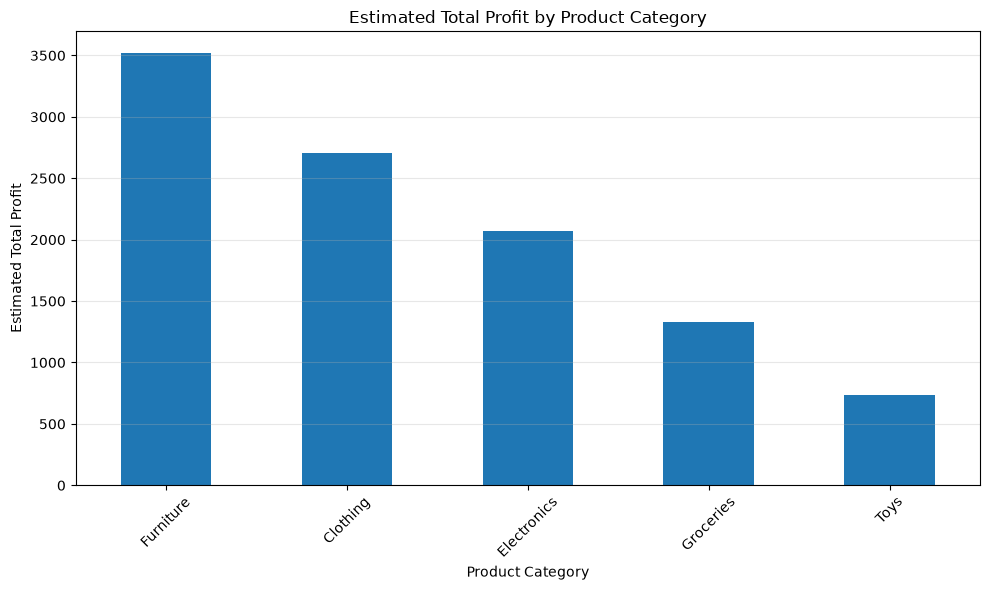

In [51]:
profit_chart = cost_model_base[
    "Estimated_Total_Profit"
].sort_values(ascending=False)

profit_chart.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Estimated Total Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Estimated Total Profit")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [52]:
total_estimated_profit = (
    cost_model_base["Estimated_Total_Profit"].sum()
)

cost_model_base["Profit_Contribution_%"] = (
    cost_model_base["Estimated_Total_Profit"]
    / total_estimated_profit
    * 100
).round(2)

display(
    cost_model_base[
        [
            "Estimated_Total_Profit",
            "Profit_Contribution_%"
        ]
    ].sort_values(
        "Profit_Contribution_%",
        ascending=False
    )
)

,Estimated_Total_Profit,Profit_Contribution_%
Category,,
Furniture,3520.30,33.95
Clothing,2707.65,26.12
Electronics,2071.85,19.98
Groceries,1329.08,12.82
Toys,739.00,7.13


In [53]:
category_performance = category_revenue_comparison[
    ["Revenue_Contribution_%"]
].join(
    cost_model_base[["Profit_Contribution_%"]]
)

category_performance["Profit_vs_Revenue_Gap"] = (
    category_performance["Profit_Contribution_%"]
    - category_performance["Revenue_Contribution_%"]
).round(2)

display(
    category_performance.sort_values(
        "Profit_Contribution_%",
        ascending=False
    )
)

,Revenue_Contribution_%,Profit_Contribution_%,Profit_vs_Revenue_Gap
Category,,,
Furniture,24.44,33.95,9.51
Clothing,18.71,26.12,7.41
Electronics,14.50,19.98,5.48
Groceries,37.09,12.82,-24.27
Toys,5.25,7.13,1.88


In [54]:
category_performance["Performance_Type"] = np.where(
    category_performance["Profit_vs_Revenue_Gap"] > 0,
    "Profit-Efficient",
    "Revenue-Heavy"
)

display(
    category_performance[
        [
            "Revenue_Contribution_%",
            "Profit_Contribution_%",
            "Profit_vs_Revenue_Gap",
            "Performance_Type"
        ]
    ]
)

,Revenue_Contribution_%,Profit_Contribution_%,Profit_vs_Revenue_Gap,Performance_Type
Category,,,,
Groceries,37.09,12.82,-24.27,Revenue-Heavy
Furniture,24.44,33.95,9.51,Profit-Efficient
Clothing,18.71,26.12,7.41,Profit-Efficient
Electronics,14.50,19.98,5.48,Profit-Efficient
Toys,5.25,7.13,1.88,Profit-Efficient


In [55]:
discount_profit_analysis["Estimated_Total_Profit"] = (
    discount_profit_analysis["Estimated_Profit_Per_Unit"]
    * discount_profit_analysis["Category"].map(
        cost_model_base["Average_Units_Sold"]
    )
).round(2)

display(
    discount_profit_analysis[
        [
            "Category",
            "Discount",
            "Estimated_Profit_Per_Unit",
            "Estimated_Total_Profit"
        ]
    ]
)

,Category,Discount,Estimated_Profit_Per_Unit,Estimated_Total_Profit
0,Clothing,0,28.61,2707.65
1,Clothing,5,25.03,2368.84
2,Clothing,10,21.46,2030.97
3,Clothing,15,17.88,1692.16
4,Clothing,20,14.31,1354.30
5,Clothing,25,10.73,1015.49
6,Electronics,0,24.95,2071.85
7,Electronics,5,20.79,1726.40
8,Electronics,10,16.63,1380.96
9,Electronics,15,12.47,1035.51


In [56]:
discount_volume_analysis = (
    df.groupby(["Category", "Discount"])
    .agg(
        Average_Units_Sold=("Units Sold", "mean"),
        Average_Demand=("Demand", "mean"),
        Number_of_Records=("Units Sold", "count")
    )
    .round(2)
    .reset_index()
)

display(discount_volume_analysis)

,Category,Discount,Average_Units_Sold,Average_Demand,Number_of_Records
0,Clothing,0,87.32,102.58,2751
1,Clothing,5,87.30,102.39,2737
2,Clothing,10,93.98,112.01,3733
3,Clothing,15,108.79,134.22,964
4,Clothing,20,109.24,131.44,965
5,Clothing,25,109.49,131.32,1010
6,Electronics,0,75.98,88.29,2081
7,Electronics,5,75.30,87.54,2045
8,Electronics,10,82.52,96.81,2751
9,Electronics,15,97.42,116.91,762


In [57]:
pricing_profit_model = discount_profit_analysis.merge(
    discount_volume_analysis[
        ["Category", "Discount", "Average_Units_Sold"]
    ],
    on=["Category", "Discount"],
    how="left"
)

pricing_profit_model["Estimated_Total_Profit"] = (
    pricing_profit_model["Estimated_Profit_Per_Unit"]
    * pricing_profit_model["Average_Units_Sold"]
).round(2)

display(
    pricing_profit_model[
        [
            "Category",
            "Discount",
            "Estimated_Profit_Per_Unit",
            "Average_Units_Sold",
            "Estimated_Total_Profit"
        ]
    ]
)

,Category,Discount,Estimated_Profit_Per_Unit,Average_Units_Sold,Estimated_Total_Profit
0,Clothing,0,28.61,87.32,2498.23
1,Clothing,5,25.03,87.30,2185.12
2,Clothing,10,21.46,93.98,2016.81
3,Clothing,15,17.88,108.79,1945.17
4,Clothing,20,14.31,109.24,1563.22
5,Clothing,25,10.73,109.49,1174.83
6,Electronics,0,24.95,75.98,1895.70
7,Electronics,5,20.79,75.30,1565.49
8,Electronics,10,16.63,82.52,1372.31
9,Electronics,15,12.47,97.42,1214.83


In [58]:
best_discount_strategy = (
    pricing_profit_model
    .loc[
        pricing_profit_model.groupby("Category")[
            "Estimated_Total_Profit"
        ].idxmax()
    ]
    [
        [
            "Category",
            "Discount",
            "Average_Units_Sold",
            "Estimated_Profit_Per_Unit",
            "Estimated_Total_Profit"
        ]
    ]
    .sort_values("Estimated_Total_Profit", ascending=False)
    .reset_index(drop=True)
)

display(best_discount_strategy)

,Category,Discount,Average_Units_Sold,Estimated_Profit_Per_Unit,Estimated_Total_Profit
0,Furniture,0,58.42,54.68,3194.41
1,Clothing,0,87.32,28.61,2498.23
2,Electronics,0,75.98,24.95,1895.70
3,Groceries,0,94.43,12.92,1220.04
4,Toys,0,73.16,9.42,689.17


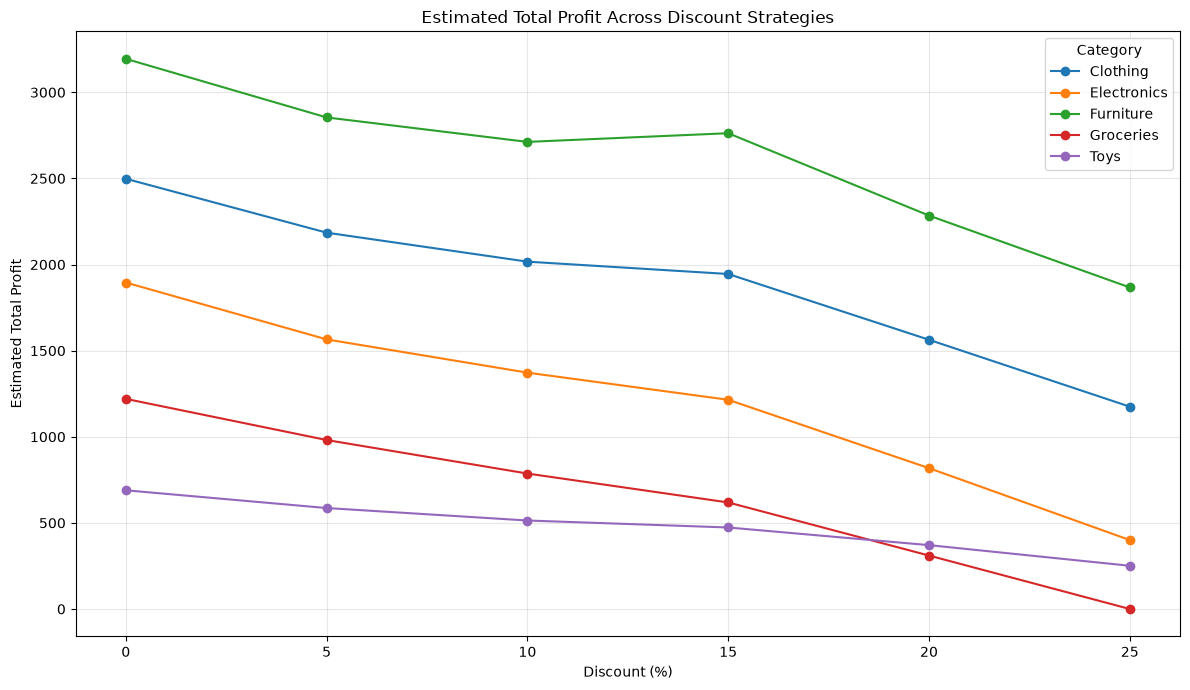

In [59]:
profit_pivot = pricing_profit_model.pivot(
    index="Discount",
    columns="Category",
    values="Estimated_Total_Profit"
)

profit_pivot.plot(
    kind="line",
    marker="o",
    figsize=(12, 7)
)

plt.title("Estimated Total Profit Across Discount Strategies")
plt.xlabel("Discount (%)")
plt.ylabel("Estimated Total Profit")
plt.legend(title="Category")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Business Analysis — Key Findings & Conclusions

## 1. Product and Category Performance
- Groceries recorded the highest average demand and sales volume.
- Furniture recorded the highest average selling price.
- Product comparisons were conducted using both Category and Product ID because Product IDs appear across multiple categories.

## 2. Pricing and Discount Analysis
- Medium-high-priced products recorded the highest average demand among price groups.
- Demand and sales generally increased at higher discount levels.
- The 20% discount group recorded the highest overall average demand.
- Higher discounts did not consistently produce higher revenue per record.

## 3. Promotion Analysis
- Records with active promotions showed higher average demand and units sold.
- Promotion and discount levels were closely associated, so their individual effects cannot be isolated from this analysis.

## 4. Regional Performance
- South recorded the highest average demand and average units sold.
- North recorded the highest total units sold, partly because it contained twice as many records as other regions.

## 5. Revenue Analysis
- Groceries contributed approximately 37.09% of total price-times-units sales value.
- Furniture contributed approximately 24.44%.
- Furniture generated a larger estimated profit contribution than its revenue contribution under the hypothetical cost assumptions.

## 6. Hypothetical Profitability Analysis
- Furniture had the highest assumed unit margin at 45%.
- Groceries had the lowest assumed unit margin at approximately 25%.
- Groceries contributed 37.09% of sales value but only 12.82% of simulated profit.
- The 0% discount scenario generated the highest estimated profit in all five categories among the tested discount levels.

**Important limitation:** Actual product costs were unavailable. Profitability results use hypothetical category-level cost assumptions and should not be interpreted as actual business profit.

## Overall Conclusion
The analysis demonstrates that high sales volume and high revenue do not necessarily translate into high profitability. Pricing and discount decisions should consider unit margins, sales volume, inventory availability and category-level performance.

The findings provide a foundation for the next stage: developing demand prediction models and using their outputs to investigate more informed pricing decisions.